# Exercise 8 - ICP

### Required libraries

Please make sure you can import the following libraries before starting:

- NumPy
- OpenCV (cv2)
- Matplotlib
- SciPy

If you are using a custom environment, install missing packages before you begin.

---

### Submission instructions

- Complete **all** tasks in this notebook (code, plots, and written answers).
- Submit **only this completed Jupyter notebook** (`.ipynb`) on teams.
- Do **not** compress it into a `.zip` file or any other archive.
- Make sure every plot has:
  - properly labeled axes,
  - a legend when appropriate,
  - a short explanation (1–3 sentences) interpreting the result.
- Your notebook should run from top to bottom without errors on a clean environment. Dont say: "But prof, it works on my setup."

---

### On tools, integrity, and survival

- Emotional breakdowns are a respected academic tradition, but please maintain **basic fluid‑dynamics control**: if you need to cry, do it *adjacent* to the laptop, not *on* it. Tech, like self‑esteem, can be damaged.
- Using LLMs is allowed, but make sure to use **your own brain**: understand every line of code and every formula you submit. If you cannot explain it, you do not own it.
- Cheating (taking someone else's work) is strictly forbidden. If you’re caught, you will fail the course immediately. More importantly, you’ll have successfully lied to the one person you are stuck with for the rest of your life: yourself. The assignment ends tonight; your relationship with your own integrity does not.

---


In this exercise you will implement the ICP algorithm for a small 2D example dataset. 

## 1.1 ICP with given correspondences [5]

Implement ICP if the point correspondences are given. 
A starting point for this exercise is given as follows. 

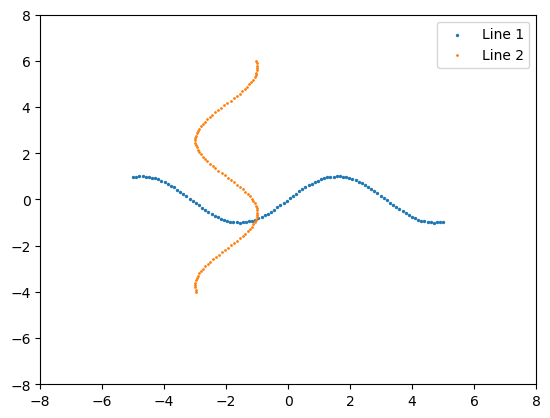

In [1]:
import ex8 as ex
import numpy as np
import matplotlib.pyplot as plt

Data = np.load('icp_data.npz')
Line1 = Data['LineGroundTruth']
Line2 = Data['LineMovedCorresp']
    
# Show the initial positions of the lines
ex.show_figure(Line1, Line2)

Following the missing parts in the algorithm, you will need to: 
  - compute mean point of an array of points in function **compute_mean()**;
  - compute cross covariance matrix **W** in **function compute_W()**;
  - compute estimated rotation and translation via **SVD** in function **compute_R_t()**;
  - apply the estimated rotation and translation and find the value of the squared error function to discover how good the estimated positions are in function **compute_error()**;
  - complete the fuction **icp_known_corresp()**.

Refer to the lecture slides for all the details. 

After you have implemented all the above, you should run the following code correctly and get the aligned Line1 and Line2.

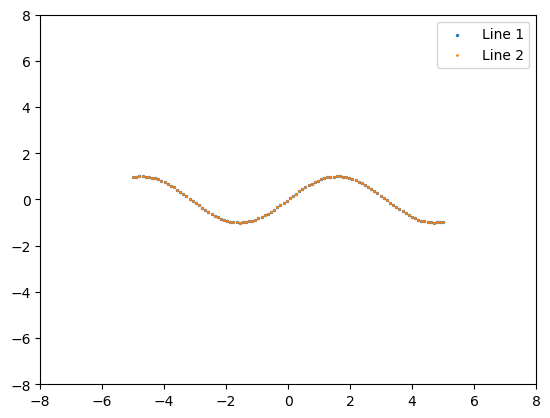

Error value is:  4.6653438083344743e-29


In [2]:
# We assume that the there are 1 to 1 correspondences for this data
QInd = np.arange(len(Line1[0]))
PInd = np.arange(len(Line2[0]))

# Perform icp given the correspondences
[Line2, E] = ex.icp_known_corresp(Line1, Line2, QInd, PInd)

# Show the adjusted positions of the lines
ex.show_figure(Line1, Line2)

# print the error
print('Error value is: ', E)

## 1.2 ICP without given correspondences [5]

Use the result of your code from the first question, to implement the full ICP algorithm.

When the point correspondences are not available. You will need to iteratively find the point correspondences and using these perform the ICP updates. 

A starting point for this exercise is given as follows.

Make you algorithm stop after convergence. 

**Hint:** The **NearestNeighbors** functions of **sklearn** library can be useful in this task.

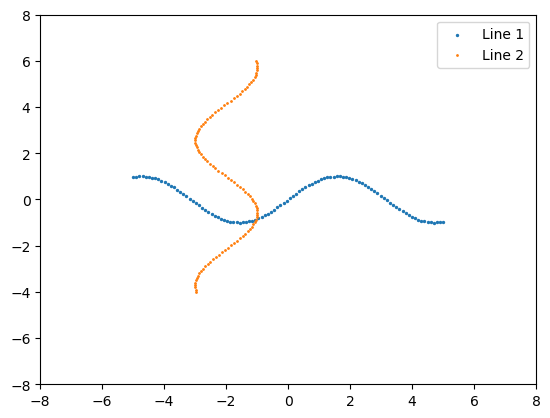

Error value on iteration 0 is: 637.4981780513156
Error value on iteration 1 is: 572.6180387287957
Error value on iteration 2 is: 428.7930266210791
Error value on iteration 3 is: 179.71515740753347
Error value on iteration 4 is: 39.087711208322055
Error value on iteration 5 is: 7.1872659859755395
Error value on iteration 6 is: 2.693160805237863
Error value on iteration 7 is: 1.4305572247681495
Error value on iteration 8 is: 0.8093513119969544
Error value on iteration 9 is: 0.45044161074830874
Error value on iteration 10 is: 0.38631275510735325
Error value on iteration 11 is: 0.36957811877359564
Error value on iteration 12 is: 0.36789607944774594
Error value on iteration 13 is: 0.3678960794477455
Converged after 13 iterations.


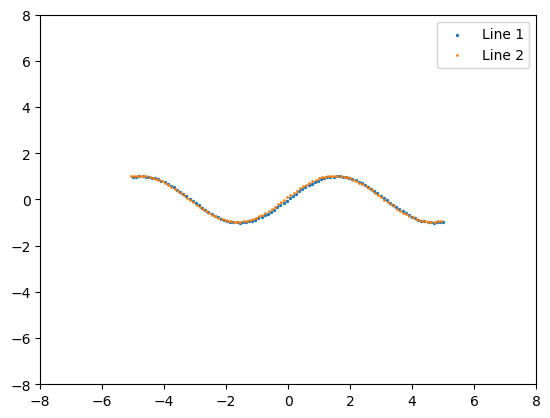

Final Error value is:  0.3678960794477455


In [4]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

# Load the data
Data = np.load('icp_data.npz')
Line1 = Data['LineGroundTruth']      # Reference (Static)
Line2 = Data['LineMovedNoCorresp']   # Source (To be moved)

MaxIter = 100
Epsilon = 0.001
E = np.inf

# show figure before alignment
ex.show_figure(Line1, Line2)

# Prepare the Nearest Neighbors model on the ground truth (Line1)
# Line1 is shape (2, N), sklearn expects (N, 2)
nn_model = NearestNeighbors(n_neighbors=1)
nn_model.fit(Line1.T)

for i in range(MaxIter):
    # 1. Find correspondences of points
    # We find the nearest neighbor in Line1 for every point in Line2
    distances, indices = nn_model.kneighbors(Line2.T)
    
    # PInd: indices of points in Line2 (simply 0 to N-1)
    # QInd: indices of the corresponding closest points in Line1
    PInd = np.arange(Line2.shape[1])
    QInd = indices.flatten()

    # 2. Update Line2 and error using known correspondence logic
    EOld = E
    [Line2, E] = ex.icp_known_corresp(Line1, Line2, QInd, PInd)
        
    print(f'Error value on iteration {i} is: {E}')

    # 3. Check for convergence
    # If the reduction in error is smaller than Epsilon, we stop
    if abs(EOld - E) < Epsilon:
        print(f'Converged after {i} iterations.')
        break

# Show the final adjusted positions
ex.show_figure(Line1, Line2)
print('Final Error value is: ', E)

**JUSTIFICATION OF THIS ASSIGNMENT**

This implementation is elegant because it mirrors how humans align things: we look at a point, find the "best match" nearby, and nudge the whole shape to make those matches fit better.

Nearest Neighbors: Since we don't know which point in Line2 belongs to which point in Line1, we use the sklearn.neighbors library. It's much faster than manual looping. By fitting the model to Line1 (the "map"), we can instantly ask: "For every point in Line2, which index in Line1 is the closest?" This gives us our QInd and PInd.

The Iterative Loop: Unlike the first exercise, we can't solve this in one shot because the "closest point" changes every time we move Line2. So, we alternate between finding the best matches and moving the points.

Convergence: We use Epsilon to prevent the code from running forever. Once the error E stops decreasing significantly (specifically, when the change is less than 0.001), it means the lines are as aligned as they are ever going to be.

Dimensionality: We have to be careful with NumPy shapes. Line1 is (2,N), but sklearn wants (N,2), so we use .T (transpose) to flip the data during the search and flip it back for the math.